## Homework 4

In this homework, we will use the lead scoring dataset Bank Marketing dataset. Download it from [here](https://raw.githubusercontent.com/alexeygrigorev/datasets/master/course_lead_scoring.csv).

In this dataset our desired target for classification task will be converted variable - has the client signed up to the platform or not.

In [1]:
import pandas as pd
import numpy as np

# read lead scoring dataset
lead_scoring = pd.read_csv('https://raw.githubusercontent.com/alexeygrigorev/datasets/master/course_lead_scoring.csv')

lead_scoring.head()

,lead_source,industry,number_of_courses_viewed,annual_income,employment_status,location,interaction_count,lead_score,converted
0,paid_ads,NaN,1,79450.0,unemployed,south_america,4,0.94,1
1,social_media,retail,1,46992.0,employed,south_america,1,0.80,0
2,events,healthcare,5,78796.0,unemployed,australia,3,0.69,1
3,paid_ads,retail,2,83843.0,NaN,australia,1,0.87,0
4,referral,education,3,85012.0,self_employed,europe,3,0.62,1


Data preparation
 - Check if the missing values are presented in the features.
 - If there are missing values:
    - For caterogiral features, replace them with 'NA'
    - For numerical features, replace with with 0.0

In [2]:
lead_scoring.isnull().sum()

lead_source                 128
industry                    134
number_of_courses_viewed      0
annual_income               181
employment_status           100
location                     63
interaction_count             0
lead_score                    0
converted                     0
dtype: int64

In [3]:
# Numerical amd categorical features
numerical_vars = lead_scoring.select_dtypes(include=['number']).columns.drop('converted').tolist()
categorical_vars = lead_scoring.select_dtypes(include=['object', 'category']).columns.tolist()

# For caterogiral features, replace missing with 'NA'
for col in categorical_vars:
    lead_scoring[col] = lead_scoring[col].fillna('NA')

# For numerical features, replace them with 0.0
for col in numerical_vars:
    lead_scoring[col] = lead_scoring[col].fillna(0.0)

lead_scoring.isnull().sum()

lead_source                 0
industry                    0
number_of_courses_viewed    0
annual_income               0
employment_status           0
location                    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Split the data into 3 parts: train/validation/test with 60%/20%/20% distribution. Use train_test_split function for that with `random_state=1`

In [4]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(lead_scoring, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

# remove target from the datasets
del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

- For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
- Use the training dataset for that

If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

In [5]:
from sklearn.metrics import roc_auc_score
# from sklearn.metrics import roc_curve
# from sklearn.metrics import auc

In [6]:
for var in numerical_vars:
    auc = roc_auc_score(y_train, df_train[var])
    print(f'AUC for {var}: {auc:.3f}')

AUC for number_of_courses_viewed: 0.764
AUC for annual_income: 0.552
AUC for interaction_count: 0.738
AUC for lead_score: 0.614


### Question 2: Training the model

Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

`LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.32
- 0.52
- 0.72
- 0.92

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

# Create a dictionary vectorizer
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_vars + numerical_vars].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

# Fit logistic regression model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,1000
,multi_class,'deprecated'


In [8]:
# Predict on validation set
val_dict = df_val[categorical_vars + numerical_vars].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]

In [9]:
# AUC of the model
round(roc_auc_score(y_val, y_pred), 3)

0.817

### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

- Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
- For each threshold, compute precision and recall
- Plot them

At which threshold precision and recall curves intersect?

- 0.145
- 0.345
- 0.545
- 0.745

In [10]:
# TP and TN
actual_positives = (y_val == 1)
actual_negatives = (y_val == 0)

# Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
# and compute precision and recall for each threshold
thresholds = np.arange(0.0, 1.0, 0.01)
scores = []

for t in thresholds:
    predicted_positives = (y_pred >= t)
    predicted_negatives = (y_pred < t)

    tp = (predicted_positives & actual_positives).sum()
    tn = (predicted_negatives & actual_negatives).sum()

    fp = (predicted_positives & actual_negatives).sum()
    fn = (predicted_negatives & actual_positives).sum()

    if tp + fp == 0 or tp + fn == 0:
        scores.append(np.float64(0))
        continue

    p = tp / (tp + fp)
    r = tp / (tp + fn)

    scores.append((t, tp, fp, fn, tn, p, r))

In [28]:
# Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
# and compute precision and recall for each threshold
thresholds = np.arange(0.0, 1.0, 0.01)
scores = []
for t in thresholds:
    actual_positives = (y_val == 1)
    actual_negatives = (y_val == 0)

    predicted_positives = (y_pred >= t)
    predicted_negatives = (y_pred < t)

    tp = int((predicted_positives & actual_positives).sum())
    tn = int((predicted_negatives & actual_negatives).sum())

    fp = int((predicted_positives & actual_negatives).sum())
    fn = int((predicted_negatives & actual_positives).sum())

    if tp + fp == 0 or tp + fn == 0:
        scores.append((t, tp, fp, fn, tn, np.nan, np.nan))
        continue

    p = tp / (tp + fp)
    r = tp / (tp + fn)

    scores.append((t, tp, fp, fn, tn, p, r))

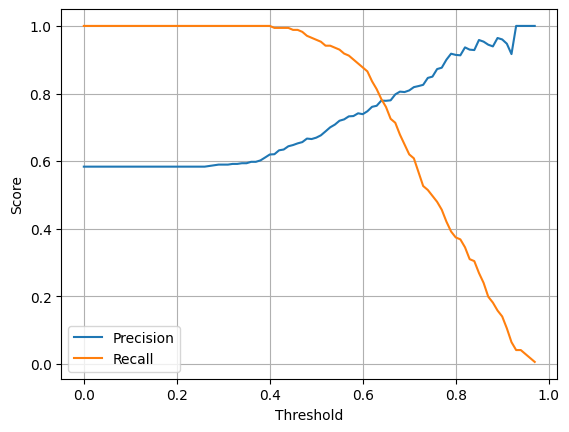

In [29]:
# Plot precision and recall for each threshodld
import matplotlib.pyplot as plt

df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall'])

plt.plot(df_scores['threshold'], df_scores['precision'], label='Precision')
plt.plot(df_scores['threshold'], df_scores['recall'], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid()
plt.show()

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?
- 0.14
- 0.34
- 0.54
- 0.74

In [55]:
# Calculate F1 score for each threshold and find the best one
f1_scores = []

for t, tp, fp, fn, tn, p, r in scores:
    if p + r == 0:
        f1_scores.append(0)
        continue
    f1 = 2 * p * r / (p + r)
    f1_scores.append(f1)

# In scores object find index of np.array([0.14, 0.34, 0.54, 0.74]) thresholds
target = np.array([0.14, 0.34, 0.54, 0.74])

# Find indices of the target values from thresholds 
indices = [i for i, t in enumerate(thresholds) if np.isclose(t, target).any()]

for index in indices:
    print(f'Threshold: {scores[index][0]:.2f}; F1: {f1_scores[index]:.3f}')

Threshold: 0.14; F1: 0.737
Threshold: 0.34; F1: 0.745
Threshold: 0.54; F1: 0.806
Threshold: 0.74; F1: 0.640


### Question 5: 5-Fold CV

Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

`KFold(n_splits=5, shuffle=True, random_state=1)`

- Iterate over different folds of df_full_train
- Split the data into train and validation
- Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
- Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.0001
- 0.006
- 0.06
- 0.36

In [56]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical_vars + numerical_vars].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical_vars + numerical_vars].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [58]:
n_splits = 5

kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

auc_scores = []

for train_idx, val_idx in tqdm(kfold.split(df_full_train)):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    auc_scores.append(auc)

print(f'CV mean (sd) AUC: {round(np.mean(auc_scores), 3)} ({round(np.std(auc_scores), 3)})')

5it [00:00, 138.13it/s]

CV mean (sd) AUC: 0.822 (0.036)


### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

- Iterate over the following `C` values: `[0.000001, 0.001, 1]`
- Initialize `KFold` with the same parameters as previously
- Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
- Compute the mean score as well as the std (round the mean and std to 3 decimal digits)

Which `C` leads to the best mean score?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

In [62]:
for C in tqdm([0.000001, 0.001, 1]):
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print(f'C={C}: CV mean (sd) AUC: {round(np.mean(scores), 3)} ({round(np.std(scores), 3)})')

100%|██████████| 3/3 [00:00<00:00, 35.46it/s]

C=1e-06: CV mean (sd) AUC: 0.56 (0.024)
C=0.001: CV mean (sd) AUC: 0.867 (0.029)
C=1: CV mean (sd) AUC: 0.822 (0.036)
